# PrizePicks Total Games Discovery (`fct_picks`)

Step 1 toward joining PrizePicks closing lines to SportRadar fixtures for tournament-level hold analysis.

**This notebook**
- Filters settled TENNIS / Total Games Core picks in BigQuery
- Aggregates to **one row per `game_id`** in SQL (player, opponent, start, closing line, handle/xGGR)
- Surfaces data-quality checks before name+time matching to SportRadar
- Matches PP games → SportRadar via both-player token-set + time window
- Joins `competition_level` and summarizes hold by tournament level

In [10]:
import sys
from pathlib import Path

import pandas as pd
from google.cloud import bigquery

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

cwd = Path.cwd().resolve()
project_root = next(
    (p for p in [cwd, *cwd.parents] if (p / "injestion").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError(f"Could not find project root from {cwd}")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from injestion.core.bq import get_client
from injestion.core.env import load_env
from injestion.sportradar.config import get_table_id as get_sr_table_id
from refined_tables.fixture_id_mapping.build import (
    match_fixtures,
    normalize_player_name,
    prepare_sportradar_matches,
)

load_env()

# fct_picks lives in the warehouse project; bill jobs there (same pattern as soccer/MLB).
WAREHOUSE_PROJECT = "warehouse-prod-prizepicks"
FCT_PICKS_TABLE = "warehouse-prod-prizepicks.core.fct_picks"
bq_client = bigquery.Client(project=WAREHOUSE_PROJECT)

# SportRadar / refined tables live under prizepicksanalytics.
analytics_client = get_client()
EVENT_SUMMARY_TABLE_ID = get_sr_table_id("event_summary")

print(f"Project root: {project_root}")
print(f"Warehouse BQ: {bq_client.project}")
print(f"Analytics BQ: {analytics_client.project}")
print(f"fct_picks: {FCT_PICKS_TABLE}")
print(f"event_summary: {EVENT_SUMMARY_TABLE_ID}")

Project root: /Users/matt.holden/Projects/tennis-origination
Warehouse BQ: warehouse-prod-prizepicks
Analytics BQ: prizepicksanalytics
fct_picks: warehouse-prod-prizepicks.core.fct_picks
fixture_stats: prizepicksanalytics.originations_tennis.refined_fixture_stats
event_summary: prizepicksanalytics.originations_tennis.sr_event_summaries


In [2]:
# Date window on created_at_utc (partition prune). Widen as needed.
REVIEW_START_DATE = "2026-06-08"
REVIEW_END_DATE = "2026-10-01"

LEAGUE_NAME = "TENNIS"
STAT_TYPE_NAME = "Total Games"

print(f"Window: [{REVIEW_START_DATE}, {REVIEW_END_DATE})")
print(f"Filter: league={LEAGUE_NAME!r} stat={STAT_TYPE_NAME!r}")

Window: [2026-06-08, 2026-10-01)
Filter: league='TENNIS' stat='Total Games'


## 1. Pull Core Total Games matches

Filter and aggregate **in BigQuery** so we download one row per `game_id`, not every pick.
Core only (`is_demon_goblin_pick = FALSE`) so Demon/Goblin lines do not pollute the main closing line.

In [3]:
match_query = f"""
WITH base AS (
  SELECT
    game_id,
    player_name,
    description AS opponent_name,
    matchup,
    projection_id,
    projection_start_time_utc,
    projection_pre_game_closing_line_score AS closing_line,
    projection_settled_score AS settled_score,
    projection_source,
    odds_type,
    opening_line_classification,
    pre_match_opening_line,
    lineup_id,
    gross_handle_usd,
    xggr_usd
  FROM `{FCT_PICKS_TABLE}`
  WHERE created_at_utc >= TIMESTAMP("{REVIEW_START_DATE}")
    AND created_at_utc < TIMESTAMP("{REVIEW_END_DATE}")
    AND league_name = "{LEAGUE_NAME}"
    AND stat_type_name = "{STAT_TYPE_NAME}"
    AND is_final = TRUE
    AND is_dnp = FALSE
    AND is_in_game_pick = FALSE
    AND is_demon_goblin_pick = FALSE
    AND projection_pre_game_closing_line_score IS NOT NULL
    AND projection_settled_score IS NOT NULL
)
SELECT
  game_id,
  ANY_VALUE(player_name) AS player_name,
  ANY_VALUE(opponent_name) AS opponent_name,
  ANY_VALUE(matchup) AS matchup,
  MIN(projection_start_time_utc) AS projection_start_time_utc,
  COUNT(DISTINCT player_name) AS n_player_names,
  COUNT(DISTINCT opponent_name) AS n_opponent_names,
  COUNT(DISTINCT projection_start_time_utc) AS n_start_times,
  COUNT(DISTINCT closing_line) AS n_closing_lines,
  COUNT(DISTINCT settled_score) AS n_settled_scores,
  COUNT(DISTINCT projection_id) AS n_projection_ids,
  COUNT(DISTINCT projection_source) AS n_projection_sources,
  COUNT(DISTINCT odds_type) AS n_odds_types,
  ANY_VALUE(closing_line) AS closing_line,
  ANY_VALUE(settled_score) AS settled_score,
  ANY_VALUE(projection_source) AS projection_source,
  ANY_VALUE(odds_type) AS odds_type,
  ANY_VALUE(opening_line_classification) AS opening_line_classification,
  ANY_VALUE(pre_match_opening_line) AS pre_match_opening_line,
  COUNT(*) AS total_picks,
  COUNT(DISTINCT lineup_id) AS total_lineups,
  SUM(gross_handle_usd) AS total_handle_usd,
  SUM(xggr_usd) AS total_xggr_usd
FROM base
GROUP BY game_id
ORDER BY total_handle_usd DESC
"""

job = bq_client.query(match_query)
match_df = job.result().to_dataframe(create_bqstorage_client=False)
print(
    f"Bytes processed: {job.total_bytes_processed / 1e9:.3f} GB | "
    f"Match-level rows: {len(match_df):,}"
)
display(match_df.head(10))

Bytes processed: 153.514 GB | Match-level rows: 3,843


,game_id,player_name,opponent_name,matchup,projection_start_time_utc,n_player_names,n_opponent_names,n_start_times,n_closing_lines,n_settled_scores,n_projection_ids,n_projection_sources,n_odds_types,closing_line,settled_score,projection_source,odds_type,opening_line_classification,pre_match_opening_line,total_picks,total_lineups,total_handle_usd,total_xggr_usd
0,TNS_game_f5jE8FLBSsGJklv5v0fptymC,Coco Gauff,Zeynep Sonmez,2026-09-01: Coco Gauff vs. Zeynep Sonmez,2026-09-01 23:14:00+00:00,1,1,1,2,1,3,1,1,17.5,19.0,auto_upload_consensus_odds,Core,Traded Line,False,80330,80330,317491.108833,-15170.638508
1,TNS_game_8KzbxQBQX4krLkKAZE0jMp40,Naomi Osaka,Karolina Muchova,2026-07-07: Naomi Osaka vs. Karolina Muchova,2026-07-07 15:10:00+00:00,1,1,1,1,1,2,1,1,23.0,23.0,auto_upload_consensus_odds,Core,Pre-Match Opening Line,True,95056,95056,303407.138833,-91.126089
2,TNS_game_ioP1OklrV7R6d58i92UGOdm4,Aryna Sabalenka,Teodora Kostovic,2026-06-29: Aryna Sabalenka vs. Teodora Kostovic,2026-06-29 16:30:00+00:00,1,1,1,1,1,1,1,1,17.5,17.0,auto_upload_consensus_odds,Core,Traded Line,False,52986,52986,127103.014667,40909.295765
3,TNS_game_F2xkW4fWwXE9M5QmBVJDxOTs,Frances Tiafoe,Terence Atmane,2026-07-01: Frances Tiafoe vs. Terence Atmane,2026-07-01 11:55:00+00:00,1,1,1,1,1,1,1,1,38.5,40.0,auto_upload_consensus_odds,Core,Traded Line,False,49280,49280,112836.459667,890.717013
4,TNS_game_oJCuQcIrDvismHPw68en83M,Hamad Medjedovic,Juan Manuel Cerundolo,2026-08-04: Hamad Medjedovic vs. Juan Manuel C...,2026-08-04 18:30:00+00:00,1,1,1,2,1,3,1,1,12.5,18.0,auto_upload_consensus_odds,Core,Traded Line,False,61236,61236,105856.250500,76176.913033
5,TNS_game_4GWqp2KAmvM6zB1XOeuYb8nw,Rebeka Masarova,Mina Hodzic,2026-09-15: Rebeka Masarova vs. Mina Hodzic,2026-09-15 15:15:00+00:00,1,1,1,3,1,3,1,1,20.0,25.0,auto_upload_consensus_odds,Core,Traded Line,False,39252,39252,104595.864500,16957.182420
6,TNS_game_kzcuyR0dbih47CBakyIchU7B,Katie Boulter,Jaqueline Cristian,2026-06-12: Katie Boulter vs. Jaqueline Cristian,2026-06-12 10:00:00+00:00,1,1,1,1,1,1,1,1,21.5,16.0,auto_upload_consensus_odds,Core,Traded Line,False,38318,38318,95758.256500,80995.124971
7,TNS_game_vRDEmwrlXi3SNk26AxuICuxh,Benjamin Bonzi,Alex Molcan,2026-09-01: Benjamin Bonzi vs. Alex Molcan,2026-09-01 22:30:00+00:00,1,1,1,4,1,4,1,1,36.5,36.0,auto_upload_consensus_odds,Core,Traded Line,False,38759,38759,83411.252500,30439.315946
8,TNS_game_70G9mRHHnruBFx2WikwLkZjw,Carlos Alcaraz,Roman Safiullin,2026-08-31: Carlos Alcaraz vs. Roman Safiullin,2026-08-31 17:31:00+00:00,1,1,1,1,1,1,1,1,36.5,30.0,auto_upload_consensus_odds,Core,Traded Line,False,32574,32574,80703.857333,22244.250254
9,TNS_game_adKgFDAPDCFlOc6fyWNqRyxT,Donna Vekic,Xinyu Wang,2026-09-22: Donna Vekic vs. Xinyu Wang,2026-09-22 06:30:00+00:00,1,1,1,2,1,2,1,1,22.5,15.0,auto_upload_consensus_odds,Core,Traded Line,False,27405,27405,78876.432000,31423.638560


In [4]:
print("projection_source (match-level ANY_VALUE):")
display(match_df["projection_source"].value_counts(dropna=False))

print("\nodds_type (match-level ANY_VALUE):")
display(match_df["odds_type"].value_counts(dropna=False))

print("\nopening_line_classification:")
display(match_df["opening_line_classification"].value_counts(dropna=False))

print("\npre_match_opening_line:")
display(match_df["pre_match_opening_line"].value_counts(dropna=False))

print(
    f"\nGames with >1 projection_source: {(match_df['n_projection_sources'] > 1).sum():,} | "
    f">1 odds_type: {(match_df['n_odds_types'] > 1).sum():,}"
)

projection_source (match-level ANY_VALUE):


projection_source
auto_upload_consensus_odds    3275
board_builder                  543
csv_upload                      25
Name: count, dtype: int64


odds_type (match-level ANY_VALUE):


odds_type
Core    3843
Name: count, dtype: int64


opening_line_classification:


opening_line_classification
Traded Line               3371
Pre-Match Opening Line     472
Name: count, dtype: int64


pre_match_opening_line:


pre_match_opening_line
False    3371
True      472
Name: count, dtype: Int64


Games with >1 projection_source: 3 | >1 odds_type: 0


## 2. Build SportRadar join keys

Match-level rows already come from BigQuery. Add normalized `pair_key` for the OJ-style both-player token-set matcher.

In [5]:
match_df = match_df.copy()
match_df["projection_start_time_utc"] = pd.to_datetime(
    match_df["projection_start_time_utc"], utc=True, errors="coerce"
)
match_df["closing_line"] = pd.to_numeric(match_df["closing_line"], errors="coerce")
match_df["settled_score"] = pd.to_numeric(match_df["settled_score"], errors="coerce")
match_df["total_handle_usd"] = pd.to_numeric(match_df["total_handle_usd"], errors="coerce")
match_df["total_xggr_usd"] = pd.to_numeric(match_df["total_xggr_usd"], errors="coerce")

match_df["norm_player"] = match_df["player_name"].map(normalize_player_name)
match_df["norm_opponent"] = match_df["opponent_name"].map(normalize_player_name)
match_df["pair_key"] = match_df.apply(
    lambda r: (
        "|".join(sorted([r["norm_player"], r["norm_opponent"]]))
        if r["norm_player"] and r["norm_opponent"]
        else None
    ),
    axis=1,
)

print(f"Match-level rows: {len(match_df):,}")
print(
    f"Date range: {match_df['projection_start_time_utc'].min()} → "
    f"{match_df['projection_start_time_utc'].max()}"
)
display(match_df.head(20))

Match-level rows: 3,843
Date range: 2026-06-08 09:00:00+00:00 → 2026-10-01 14:00:00+00:00


,game_id,player_name,opponent_name,matchup,projection_start_time_utc,n_player_names,n_opponent_names,n_start_times,n_closing_lines,n_settled_scores,n_projection_ids,n_projection_sources,n_odds_types,closing_line,settled_score,projection_source,odds_type,opening_line_classification,pre_match_opening_line,total_picks,total_lineups,total_handle_usd,total_xggr_usd,norm_player,norm_opponent,pair_key
0,TNS_game_f5jE8FLBSsGJklv5v0fptymC,Coco Gauff,Zeynep Sonmez,2026-09-01: Coco Gauff vs. Zeynep Sonmez,2026-09-01 23:14:00+00:00,1,1,1,2,1,3,1,1,17.5,19.0,auto_upload_consensus_odds,Core,Traded Line,False,80330,80330,317491.108833,-15170.638508,coco_gauff,sonmez_zeynep,coco_gauff|sonmez_zeynep
1,TNS_game_8KzbxQBQX4krLkKAZE0jMp40,Naomi Osaka,Karolina Muchova,2026-07-07: Naomi Osaka vs. Karolina Muchova,2026-07-07 15:10:00+00:00,1,1,1,1,1,2,1,1,23.0,23.0,auto_upload_consensus_odds,Core,Pre-Match Opening Line,True,95056,95056,303407.138833,-91.126089,naomi_osaka,karolina_muchova,karolina_muchova|naomi_osaka
2,TNS_game_ioP1OklrV7R6d58i92UGOdm4,Aryna Sabalenka,Teodora Kostovic,2026-06-29: Aryna Sabalenka vs. Teodora Kostovic,2026-06-29 16:30:00+00:00,1,1,1,1,1,1,1,1,17.5,17.0,auto_upload_consensus_odds,Core,Traded Line,False,52986,52986,127103.014667,40909.295765,aryna_sabalenka,kostovic_teodora,aryna_sabalenka|kostovic_teodora
3,TNS_game_F2xkW4fWwXE9M5QmBVJDxOTs,Frances Tiafoe,Terence Atmane,2026-07-01: Frances Tiafoe vs. Terence Atmane,2026-07-01 11:55:00+00:00,1,1,1,1,1,1,1,1,38.5,40.0,auto_upload_consensus_odds,Core,Traded Line,False,49280,49280,112836.459667,890.717013,frances_tiafoe,atmane_terence,atmane_terence|frances_tiafoe
4,TNS_game_oJCuQcIrDvismHPw68en83M,Hamad Medjedovic,Juan Manuel Cerundolo,2026-08-04: Hamad Medjedovic vs. Juan Manuel C...,2026-08-04 18:30:00+00:00,1,1,1,2,1,3,1,1,12.5,18.0,auto_upload_consensus_odds,Core,Traded Line,False,61236,61236,105856.250500,76176.913033,hamad_medjedovic,cerundolo_juan_manuel,cerundolo_juan_manuel|hamad_medjedovic
5,TNS_game_4GWqp2KAmvM6zB1XOeuYb8nw,Rebeka Masarova,Mina Hodzic,2026-09-15: Rebeka Masarova vs. Mina Hodzic,2026-09-15 15:15:00+00:00,1,1,1,3,1,3,1,1,20.0,25.0,auto_upload_consensus_odds,Core,Traded Line,False,39252,39252,104595.864500,16957.182420,masarova_rebeka,hodzic_mina,hodzic_mina|masarova_rebeka
6,TNS_game_kzcuyR0dbih47CBakyIchU7B,Katie Boulter,Jaqueline Cristian,2026-06-12: Katie Boulter vs. Jaqueline Cristian,2026-06-12 10:00:00+00:00,1,1,1,1,1,1,1,1,21.5,16.0,auto_upload_consensus_odds,Core,Traded Line,False,38318,38318,95758.256500,80995.124971,boulter_katie,cristian_jaqueline,boulter_katie|cristian_jaqueline
7,TNS_game_vRDEmwrlXi3SNk26AxuICuxh,Benjamin Bonzi,Alex Molcan,2026-09-01: Benjamin Bonzi vs. Alex Molcan,2026-09-01 22:30:00+00:00,1,1,1,4,1,4,1,1,36.5,36.0,auto_upload_consensus_odds,Core,Traded Line,False,38759,38759,83411.252500,30439.315946,benjamin_bonzi,alex_molcan,alex_molcan|benjamin_bonzi
8,TNS_game_70G9mRHHnruBFx2WikwLkZjw,Carlos Alcaraz,Roman Safiullin,2026-08-31: Carlos Alcaraz vs. Roman Safiullin,2026-08-31 17:31:00+00:00,1,1,1,1,1,1,1,1,36.5,30.0,auto_upload_consensus_odds,Core,Traded Line,False,32574,32574,80703.857333,22244.250254,alcaraz_carlos,roman_safiullin,alcaraz_carlos|roman_safiullin
9,TNS_game_adKgFDAPDCFlOc6fyWNqRyxT,Donna Vekic,Xinyu Wang,2026-09-22: Donna Vekic vs. Xinyu Wang,2026-09-22 06:30:00+00:00,1,1,1,2,1,2,1,1,22.5,15.0,auto_upload_consensus_odds,Core,Traded Line,False,27405,27405,78876.432000,31423.638560,donna_vekic,wang_xinyu,donna_vekic|wang_xinyu


## 3. Data-quality checks

Flag games that are risky to match or to treat as a single closing line.

In [6]:
qc = {
    "n_matches": len(match_df),
    "missing_opponent": int(match_df["opponent_name"].isna().sum()),
    "missing_pair_key": int(match_df["pair_key"].isna().sum()),
    "missing_start_time": int(match_df["projection_start_time_utc"].isna().sum()),
    "missing_closing_line": int(match_df["closing_line"].isna().sum()),
    "multi_player_name": int((match_df["n_player_names"] > 1).sum()),
    "multi_opponent_name": int((match_df["n_opponent_names"] > 1).sum()),
    "multi_start_time": int((match_df["n_start_times"] > 1).sum()),
    "multi_closing_line": int((match_df["n_closing_lines"] > 1).sum()),
    "multi_settled_score": int((match_df["n_settled_scores"] > 1).sum()),
    "multi_projection_id": int((match_df["n_projection_ids"] > 1).sum()),
    "duplicate_pair_key_start": int(
        match_df.duplicated(subset=["pair_key", "projection_start_time_utc"], keep=False).sum()
    ),
}

qc_df = pd.DataFrame({"check": list(qc.keys()), "count": list(qc.values())})
display(qc_df)

problem_mask = (
    (match_df["n_player_names"] > 1)
    | (match_df["n_opponent_names"] > 1)
    | (match_df["n_start_times"] > 1)
    | (match_df["n_closing_lines"] > 1)
    | (match_df["n_settled_scores"] > 1)
    | match_df["pair_key"].isna()
    | match_df["projection_start_time_utc"].isna()
)
problem_df = match_df.loc[problem_mask].copy()
print(f"\nProblem match rows: {len(problem_df):,}")
if len(problem_df):
    display(
        problem_df[
            [
                "game_id",
                "player_name",
                "opponent_name",
                "projection_start_time_utc",
                "n_player_names",
                "n_opponent_names",
                "n_start_times",
                "n_closing_lines",
                "n_settled_scores",
                "n_projection_ids",
                "closing_line",
                "settled_score",
            ]
        ].head(50)
    )

,check,count
0,n_matches,3843
1,missing_opponent,0
2,missing_pair_key,0
3,missing_start_time,0
4,missing_closing_line,0
5,multi_player_name,7
6,multi_opponent_name,7
7,multi_start_time,14
8,multi_closing_line,495
9,multi_settled_score,1



Problem match rows: 501


,game_id,player_name,opponent_name,projection_start_time_utc,n_player_names,n_opponent_names,n_start_times,n_closing_lines,n_settled_scores,n_projection_ids,closing_line,settled_score
0,TNS_game_f5jE8FLBSsGJklv5v0fptymC,Coco Gauff,Zeynep Sonmez,2026-09-01 23:14:00+00:00,1,1,1,2,1,3,17.5,19.0
4,TNS_game_oJCuQcIrDvismHPw68en83M,Hamad Medjedovic,Juan Manuel Cerundolo,2026-08-04 18:30:00+00:00,1,1,1,2,1,3,12.5,18.0
5,TNS_game_4GWqp2KAmvM6zB1XOeuYb8nw,Rebeka Masarova,Mina Hodzic,2026-09-15 15:15:00+00:00,1,1,1,3,1,3,20.0,25.0
7,TNS_game_vRDEmwrlXi3SNk26AxuICuxh,Benjamin Bonzi,Alex Molcan,2026-09-01 22:30:00+00:00,1,1,1,4,1,4,36.5,36.0
9,TNS_game_adKgFDAPDCFlOc6fyWNqRyxT,Donna Vekic,Xinyu Wang,2026-09-22 06:30:00+00:00,1,1,1,2,1,2,22.5,15.0
16,TNS_game_xjAf5R6GE5Q2olAVQs5Py4EM,Elena Rybakina,Thea Frodin,2026-09-01 18:45:00+00:00,1,1,1,2,1,2,17.0,17.0
17,TNS_game_UyiA8s0Dv7LDbF3Qw6YEAU8F,Luca Van Assche,Hugo Gaston,2026-07-25 16:30:00+00:00,1,1,1,2,1,2,22.5,22.0
19,TNS_game_AERqYTcgnSlx2G8pjgG2ygsp,Valeria Savinykh,Emma SI Yu Dong,2026-07-28 01:40:00+00:00,1,1,1,2,1,2,20.0,17.0
21,TNS_game_96BMubE1iHlzUPQVe3vnO4or,Nuno Borges,Tristan Boyer,2026-06-29 13:10:00+00:00,1,1,1,2,1,2,38.5,33.0
23,TNS_game_8pFsjabMcwnOLLiT0tQFJZMw,James Duckworth,Diego Dedura-Palomero,2026-06-09 15:30:00+00:00,1,1,1,3,1,3,23.0,19.0


In [7]:
# Clean cohort for matching: unique identity + single closing/settled values.
clean_df = match_df.loc[
    match_df["pair_key"].notna()
    & match_df["projection_start_time_utc"].notna()
    & match_df["closing_line"].notna()
    & (match_df["n_player_names"] == 1)
    & (match_df["n_opponent_names"] == 1)
    & (match_df["n_start_times"] == 1)
    & (match_df["n_closing_lines"] == 1)
    & (match_df["n_settled_scores"] == 1)
].copy()

clean_df["hold_pct"] = (
    100.0 * clean_df["total_xggr_usd"] / clean_df["total_handle_usd"]
).where(clean_df["total_handle_usd"] > 0)

print(f"Clean match rows: {len(clean_df):,} / {len(match_df):,}")
print(
    f"Total handle: ${clean_df['total_handle_usd'].sum():,.0f} | "
    f"Total xGGR: ${clean_df['total_xggr_usd'].sum():,.0f} | "
    f"Overall hold: {100 * clean_df['total_xggr_usd'].sum() / clean_df['total_handle_usd'].sum():.2f}%"
)
display(
    clean_df[
        [
            "game_id",
            "player_name",
            "opponent_name",
            "pair_key",
            "projection_start_time_utc",
            "closing_line",
            "settled_score",
            "total_picks",
            "total_handle_usd",
            "total_xggr_usd",
            "hold_pct",
        ]
    ]
    .sort_values("total_handle_usd", ascending=False)
    .head(25)
)

Clean match rows: 3,342 / 3,843
Total handle: $16,014,738 | Total xGGR: $4,577,043 | Overall hold: 28.58%


,game_id,player_name,opponent_name,pair_key,projection_start_time_utc,closing_line,settled_score,total_picks,total_handle_usd,total_xggr_usd,hold_pct
1,TNS_game_8KzbxQBQX4krLkKAZE0jMp40,Naomi Osaka,Karolina Muchova,karolina_muchova|naomi_osaka,2026-07-07 15:10:00+00:00,23.0,23.0,95056,303407.138833,-91.126089,-0.030034
2,TNS_game_ioP1OklrV7R6d58i92UGOdm4,Aryna Sabalenka,Teodora Kostovic,aryna_sabalenka|kostovic_teodora,2026-06-29 16:30:00+00:00,17.5,17.0,52986,127103.014667,40909.295765,32.185937
3,TNS_game_F2xkW4fWwXE9M5QmBVJDxOTs,Frances Tiafoe,Terence Atmane,atmane_terence|frances_tiafoe,2026-07-01 11:55:00+00:00,38.5,40.0,49280,112836.459667,890.717013,0.789388
6,TNS_game_kzcuyR0dbih47CBakyIchU7B,Katie Boulter,Jaqueline Cristian,boulter_katie|cristian_jaqueline,2026-06-12 10:00:00+00:00,21.5,16.0,38318,95758.256500,80995.124971,84.582915
8,TNS_game_70G9mRHHnruBFx2WikwLkZjw,Carlos Alcaraz,Roman Safiullin,alcaraz_carlos|roman_safiullin,2026-08-31 17:31:00+00:00,36.5,30.0,32574,80703.857333,22244.250254,27.562809
10,TNS_game_p74l6Pvfz5T7IYBLtu81fb7O,Ugo Humbert,Zizou Bergs,bergs_zizou|humbert_ugo,2026-06-30 11:30:00+00:00,39.0,48.0,36198,72822.652500,34504.381586,47.381385
11,TNS_game_IwAVOUZyXruCnTbKyL2MXVO9,Alexander Zverev,Yannick Hanfmann,alexander_zverev|hanfmann_yannick,2026-06-18 13:40:00+00:00,22.5,22.0,28870,72182.064000,38752.505278,53.687167
12,TNS_game_QhusqYGCdlhn9f2P7Zb2kl82,Sara Sorribes Tormo,Viktoria Morvayova,morvayova_viktoria|sara_sorribes_tormo,2026-09-29 04:46:00+00:00,19.5,27.0,25278,71825.170833,20617.153783,28.704636
13,TNS_game_qj9cPfnh5Sntg1rHL8eYS1Hh,Gabriela Knutson,Irem Kurt,gabriela_knutson|irem_kurt,2026-07-13 14:00:00+00:00,17.5,26.0,30488,71688.320000,22625.902128,31.561490
14,TNS_game_SVXxM9IuHOZx8J2Ds0IZz4fJ,Jannik Sinner,Alexander Zverev,alexander_zverev|jannik_sinner,2026-07-12 15:09:00+00:00,38.5,45.0,31039,70982.136167,45837.400870,64.575967


## 4. Preview for SportRadar matching

These are the fields the next step will join to `sr_event_summaries` via the same both-player token-set + time-window logic used for OddsJam.

In [8]:
preview_cols = [
    "game_id",
    "player_name",
    "opponent_name",
    "pair_key",
    "projection_start_time_utc",
    "closing_line",
    "settled_score",
    "total_handle_usd",
    "total_xggr_usd",
]
pp_match_keys = clean_df[preview_cols].sort_values("projection_start_time_utc").reset_index(drop=True)

print(f"Ready for SR matching: {len(pp_match_keys):,} games")
display(pp_match_keys.head(30))

# Optional local checkpoint for the next notebook step.
out_path = project_root / "refined_tables" / "fixture_id_mapping" / "pp_total_games_match_keys.parquet"
pp_match_keys.to_parquet(out_path, index=False)
print(f"Wrote {out_path}")

Ready for SR matching: 3,342 games


,game_id,player_name,opponent_name,pair_key,projection_start_time_utc,closing_line,settled_score,total_handle_usd,total_xggr_usd
0,TNS_game_QEp3eh2G2ZoG95ptaQk77Xjv,Alejandro Davidovich Fokina,Mattia Bellucci,alejandro_davidovich_fokina|bellucci_mattia,2026-06-08 09:00:00+00:00,22.5,28.0,4850.378333,-2181.765111
1,TNS_game_oe2qVoM6e2TUsg590Y3qifzE,Ella McDonald,Ranah Akua Stoiber,akua_ranah_stoiber|ella_mcdonald,2026-06-08 10:00:00+00:00,20.5,18.0,2853.732667,2029.691436
2,TNS_game_k2Dn1usFP2rP7gJXiRhhLmgw,Xiyu Wang,Laura Samson,laura_samson|wang_xiyu,2026-06-08 10:30:00+00:00,20.5,25.0,1103.330833,682.724167
3,TNS_game_Hnd5mcfpH2oWYRCSZ3EtxksR,Benjamin Bonzi,Mees Rottgering,benjamin_bonzi|mees_rottgering,2026-06-08 10:33:00+00:00,23.5,20.0,12.583333,12.583333
4,TNS_game_M0rD1MfEfeFkTQoz6hldyfmz,Daria Kasatkina,Robin Montgomery,daria_kasatkina|montgomery_robin,2026-06-08 10:59:00+00:00,21.5,28.0,2268.220833,160.281167
5,TNS_game_P4FgOan7vXh15i2SQEa6IdOt,Elise Mertens,Bianca Andreescu,andreescu_bianca|elise_mertens,2026-06-08 11:04:00+00:00,20.5,15.0,5263.459500,-959.927692
6,TNS_game_lXPFN8f93Dc1KhUe7IJ1NUHw,Martin Landaluce,Pierre-Hugues Herbert,herbert_hugues_pierre|landaluce_martin,2026-06-08 11:15:00+00:00,24.5,31.0,6297.443167,-2604.818415
7,TNS_game_yipKV8Cl2iivukTew08Qp6l7,Harmony Tan,Emily Appleton,appleton_emily|harmony_tan,2026-06-08 12:00:00+00:00,21.5,21.0,2454.061833,-1495.464167
8,TNS_game_V2s0v2t1j1whC9j8AbMuHAd,Paula Badosa,Daria Snigur,badosa_paula|daria_snigur,2026-06-08 12:30:00+00:00,21.5,20.0,3052.865667,1448.328500
9,TNS_game_TmYM6bZECB1PZXBqFVvgNcr,Liudmila Samsonova,Harriet Dart,dart_harriet|liudmila_samsonova,2026-06-08 13:45:00+00:00,20.5,31.0,2901.347167,1718.191333


Wrote /Users/matt.holden/Projects/tennis-origination/refined_tables/fixture_id_mapping/pp_total_games_match_keys.parquet


## 5. Match PrizePicks games → SportRadar (`sr_event_summaries`)

Match directly to event summaries (not `refined_fixture_stats`) so we keep games that lack PBP aggregates.
Reuse the OJ fixture matcher: exact both-player `pair_key`, ±12h window on `start_time`, mutual nearest neighbor with 120-minute clear-winner margin.
`match_fixtures` expects OJ-style column names, so we map `game_id` → `fixture_id` and PP start → `start_date` for the call only.

In [14]:
event_summary_df = analytics_client.query(
    f"""
    SELECT
      sport_event_id,
      home_competitor_name,
      away_competitor_name,
      start_time,
      category_name,
      competition_level,
      competition_name,
      season_id,
      season_name
    FROM `{EVENT_SUMMARY_TABLE_ID}`
    """
).to_dataframe(create_bqstorage_client=False)
event_summary_df = event_summary_df.drop_duplicates(subset=["sport_event_id"], keep="first")

# prepare_sportradar_matches expects first_event_time; event summaries use start_time.
sr_input = event_summary_df.rename(columns={"start_time": "first_event_time"})
sr_matches = prepare_sportradar_matches(sr_input)

print(f"SR event_summary rows: {len(event_summary_df):,}")
print(f"SR prepared match rows: {len(sr_matches):,}")
display(sr_matches.head(5))

SR event_summary rows: 34,410
SR prepared match rows: 34,410


,first_event_time,away_competitor_name,sport_event_id,home_competitor_name,norm_home,norm_away,pair_key
0,2025-11-24 02:00:00+00:00,"Goyal, Medhir",sr:sport_event:66040546,"Mo, Ye Cong",cong_mo_ye,goyal_medhir,cong_mo_ye|goyal_medhir
1,2025-11-24 05:00:00+00:00,"Kusuhara, Yusuke",sr:sport_event:66040550,"Santillan, Akira",akira_santillan,kusuhara_yusuke,akira_santillan|kusuhara_yusuke
2,2025-11-24 02:00:00+00:00,"Luo, Jun Hao",sr:sport_event:66040544,"Rawat, Sidharth",rawat_sidharth,hao_jun_luo,hao_jun_luo|rawat_sidharth
3,2025-11-24 03:30:00+00:00,"Park, Uisung",sr:sport_event:66040548,"Jones, Maximus",jones_maximus,park_uisung,jones_maximus|park_uisung
4,2025-11-24 06:10:00+00:00,"Han, Jiangxue",sr:sport_event:66040800,"Kobori, Momoko",kobori_momoko,han_jiangxue,han_jiangxue|kobori_momoko


In [15]:
pp_pairs = (
    clean_df.loc[:, ["game_id", "projection_start_time_utc", "pair_key", "norm_player", "norm_opponent"]]
    .rename(
        columns={
            "game_id": "fixture_id",
            "projection_start_time_utc": "start_date",
            "norm_player": "oj_player_a",
            "norm_opponent": "oj_player_b",
        }
    )
    .copy()
)
pp_pairs["start_date"] = pd.to_datetime(pp_pairs["start_date"], utc=True, errors="coerce")
pp_pairs = pp_pairs.dropna(subset=["fixture_id", "pair_key", "start_date"]).reset_index(drop=True)

results = match_fixtures(sr_matches, pp_pairs)
accepted = results["accepted"].copy()
ambiguous = results["ambiguous"].copy()
candidates = results["candidates"].copy()

matched_game_ids = set(accepted["fixture_id"]) if not accepted.empty else set()
unmatched_pp = clean_df.loc[~clean_df["game_id"].isin(matched_game_ids)].copy()

print(f"PP clean games:     {len(clean_df):,}")
print(f"Candidate links:    {len(candidates):,}")
print(f"Accepted matches:   {len(accepted):,} ({100 * len(accepted) / len(clean_df):.1f}%)")
print(f"Ambiguous links:    {len(ambiguous):,}")
print(f"Unmatched PP games: {len(unmatched_pp):,}")
if not accepted.empty:
    print(
        f"Abs time delta minutes — median {accepted['abs_time_delta_minutes'].median():.1f} | "
        f"p95 {accepted['abs_time_delta_minutes'].quantile(0.95):.1f}"
    )
    display(
        accepted[
            [
                "fixture_id",
                "sport_event_id",
                "home_competitor_name",
                "away_competitor_name",
                "start_date",
                "first_event_time",
                "abs_time_delta_minutes",
                "match_method",
            ]
        ].head(15)
    )

PP clean games:     3,342
Candidate links:    2,341
Accepted matches:   2,341 (70.0%)
Ambiguous links:    0
Unmatched PP games: 1,001
Abs time delta minutes — median 5.0 | p95 50.0


,fixture_id,sport_event_id,home_competitor_name,away_competitor_name,start_date,first_event_time,abs_time_delta_minutes,match_method
0,TNS_game_PAfJ8ZxME8EU5z2F7Z4B2wiR,sr:sport_event:72261972,"Moreno de Alboran, Nicolas","Mayot, Harold",2026-06-22 11:10:00+00:00,2026-06-22 11:35:00+00:00,25.0,both_players_token_set
1,TNS_game_lciEuifatn0aKwRftffGcYSR,sr:sport_event:72261926,"Llamas Ruiz, Pablo","Added, Dan",2026-06-22 12:55:00+00:00,2026-06-22 12:55:00+00:00,0.0,both_players_token_set
2,TNS_game_6FrF1vb25FABxnHrEpx8iSgH,sr:sport_event:72261968,"Brancaccio, Raul","Gea, Arthur",2026-06-22 11:45:00+00:00,2026-06-22 11:45:00+00:00,0.0,both_players_token_set
3,TNS_game_vWusWAMDQpnoNweYRhytxNA4,sr:sport_event:72261956,"Gomez, Federico Agustin","Tabur, Clement",2026-06-22 10:08:00+00:00,2026-06-22 10:00:00+00:00,8.0,both_players_token_set
4,TNS_game_cJEikC4dniRDXy0pdTjkQkaB,sr:sport_event:72261958,"Bu, Yunchaokete","Dellien, Hugo",2026-06-22 10:10:00+00:00,2026-06-22 10:00:00+00:00,10.0,both_players_token_set
5,TNS_game_L3Njvs3lGp7vVHcPxpxZWIti,sr:sport_event:72261934,"Basilashvili, Nikoloz","Ymer, Elias",2026-06-22 12:30:00+00:00,2026-06-22 12:25:00+00:00,5.0,both_players_token_set
6,TNS_game_iU1qfhS9sQD8dgto3hCPZOPL,sr:sport_event:72261872,"Schwaerzler, Joel","O'Connell, Christopher",2026-06-22 15:42:00+00:00,2026-06-22 15:45:00+00:00,3.0,both_players_token_set
7,TNS_game_Z1jaXXw53iYP6buIYXkxowew,sr:sport_event:72261878,"McDonald, Mackenzie","Meligeni Alves, Felipe",2026-06-22 16:25:00+00:00,2026-06-22 16:25:00+00:00,0.0,both_players_token_set
8,TNS_game_QZ53bopN42IT9AiWXi0CSk92,sr:sport_event:72261852,"Den Ouden, Guy","Zhou, Yi",2026-06-22 13:15:00+00:00,2026-06-22 13:15:00+00:00,0.0,both_players_token_set
9,TNS_game_EHgcUA1M41nFZ356XXixEdL,sr:sport_event:72286788,"Moro Canas, Alejandro","Mayot, Harold",2026-06-24 16:05:00+00:00,2026-06-24 16:00:00+00:00,5.0,both_players_token_set


### Unmatched PP debug

Split unmatched games into:
- **no_pair_key** — normalized player pair never appears in SportRadar event summaries
- **pair_key_outside_window** — pair exists on SR, but no candidate within ±12h
- **other** — pair existed in candidates but failed mutual/margin rules (should be rare here)

In [13]:
sr_pair_keys = set(sr_matches["pair_key"].dropna().astype(str))
candidate_pp_ids = set(candidates["fixture_id"]) if not candidates.empty else set()

unmatched_debug = unmatched_pp.copy()
unmatched_debug["pair_in_sr"] = unmatched_debug["pair_key"].astype(str).isin(sr_pair_keys)
unmatched_debug["had_candidate"] = unmatched_debug["game_id"].isin(candidate_pp_ids)
unmatched_debug["unmatched_reason"] = "other"
unmatched_debug.loc[~unmatched_debug["pair_in_sr"], "unmatched_reason"] = "no_pair_key"
unmatched_debug.loc[
    unmatched_debug["pair_in_sr"] & ~unmatched_debug["had_candidate"],
    "unmatched_reason",
] = "pair_key_outside_window"

print("Unmatched reason counts:")
display(unmatched_debug["unmatched_reason"].value_counts())

preview_cols = [
    "game_id",
    "player_name",
    "opponent_name",
    "pair_key",
    "projection_start_time_utc",
    "closing_line",
    "settled_score",
    "total_handle_usd",
    "unmatched_reason",
]

for reason in ["no_pair_key", "pair_key_outside_window", "other"]:
    subset = unmatched_debug.loc[unmatched_debug["unmatched_reason"] == reason].sort_values(
        "total_handle_usd", ascending=False
    )
    print(f"\n=== {reason}: {len(subset):,} games (top handle) ===")
    if len(subset):
        display(subset[preview_cols].head(15))

# For a few no_pair_key examples, show nearest SR names sharing either player token set.
sample_no_pair = unmatched_debug.loc[
    unmatched_debug["unmatched_reason"] == "no_pair_key"
].sort_values("total_handle_usd", ascending=False).head(5)

if len(sample_no_pair):
    print("\n=== SR rows sharing one normalized player (name-miss hints) ===")
    for _, row in sample_no_pair.iterrows():
        player_hits = sr_matches.loc[
            (sr_matches["norm_home"] == row["norm_player"])
            | (sr_matches["norm_away"] == row["norm_player"])
            | (sr_matches["norm_home"] == row["norm_opponent"])
            | (sr_matches["norm_away"] == row["norm_opponent"])
        ].copy()
        print(
            f"\nPP: {row['player_name']} vs {row['opponent_name']} | "
            f"start={row['projection_start_time_utc']} | pair_key={row['pair_key']}"
        )
        if player_hits.empty:
            print("  No SR fixtures contain either normalized player name.")
        else:
            player_hits["abs_hours_from_pp"] = (
                (
                    pd.to_datetime(player_hits["first_event_time"], utc=True)
                    - pd.to_datetime(row["projection_start_time_utc"], utc=True)
                ).dt.total_seconds()
                / 3600.0
            ).abs()
            display(
                player_hits.sort_values("abs_hours_from_pp")[
                    [
                        "sport_event_id",
                        "home_competitor_name",
                        "away_competitor_name",
                        "pair_key",
                        "first_event_time",
                        "abs_hours_from_pp",
                    ]
                ].head(5)
            )

Unmatched reason counts:


unmatched_reason
no_pair_key                1864
pair_key_outside_window     168
Name: count, dtype: int64


=== no_pair_key: 1,864 games (top handle) ===


,game_id,player_name,opponent_name,pair_key,projection_start_time_utc,closing_line,settled_score,total_handle_usd,unmatched_reason
6,TNS_game_kzcuyR0dbih47CBakyIchU7B,Katie Boulter,Jaqueline Cristian,boulter_katie|cristian_jaqueline,2026-06-12 10:00:00+00:00,21.5,16.0,95758.256500,no_pair_key
12,TNS_game_QhusqYGCdlhn9f2P7Zb2kl82,Sara Sorribes Tormo,Viktoria Morvayova,morvayova_viktoria|sara_sorribes_tormo,2026-09-29 04:46:00+00:00,19.5,27.0,71825.170833,no_pair_key
13,TNS_game_qj9cPfnh5Sntg1rHL8eYS1Hh,Gabriela Knutson,Irem Kurt,gabriela_knutson|irem_kurt,2026-07-13 14:00:00+00:00,17.5,26.0,71688.320000,no_pair_key
18,TNS_game_cElZjSPN8TZFXY5dmXevUVC3,Lilli Tagger,Marianne Argyrokastriti,argyrokastriti_marianne|lilli_tagger,2026-07-13 14:30:00+00:00,16.5,14.0,65986.324000,no_pair_key
24,TNS_game_GphjlVmj9ZNjQe6RG6fizZH0,Anna Blinkova,Erika Andreeva,andreeva_erika|anna_blinkova,2026-07-06 12:30:00+00:00,21.0,25.0,56521.846500,no_pair_key
29,TNS_game_tZf5bUbJljPei48TxBrebqzz,Arthur Fils,Matteo Berrettini,arthur_fils|berrettini_matteo,2026-07-02 14:05:00+00:00,40.5,40.0,53525.747000,no_pair_key
31,TNS_game_Ue9AadtQyI37bUwmLHhUNQnb,Christopher O'Connell,Mackenzie McDonald,christopher_connell_o|mackenzie_mcdonald,2026-06-25 10:00:00+00:00,39.0,29.0,52431.221167,no_pair_key
32,TNS_game_9eQMrDmog4PGUzA8hfat65ZB,Ethan Quinn,Luciano Darderi,darderi_luciano|ethan_quinn,2026-06-29 14:00:00+00:00,39.5,33.0,52260.361833,no_pair_key
34,TNS_game_Rt3nAJXoYGMj2vbVzzUqwVQ,Jeffrey John Wolf,Luciano Emanuel Ambrogi,ambrogi_emanuel_luciano|jeffrey_john_wolf,2026-09-14 20:40:00+00:00,18.0,14.0,51648.338000,no_pair_key
38,TNS_game_P2o9gD4wyC2D5eVzSjDMABlv,Jeline Vandromme,Diana Martynov,diana_martynov|jeline_vandromme,2026-07-07 10:35:00+00:00,19.0,18.0,50325.547000,no_pair_key



=== pair_key_outside_window: 168 games (top handle) ===


...

,sport_event_id,home_competitor_name,away_competitor_name,pair_key,first_event_time,abs_hours_from_pp
5397,sr:sport_event:73146490,"Zhang, Shuai","Knutson, Gabriela",gabriela_knutson|shuai_zhang,2026-07-25 20:02:25+00:00,294.040278
3564,sr:sport_event:74105030,"Knutson, Gabriela","Gorgodze, Ekaterine",ekaterine_gorgodze|gabriela_knutson,2026-08-27 15:48:06+00:00,1081.801667
2453,sr:sport_event:74150436,"Knutson, Gabriela","Lys, Eva",eva_lys|gabriela_knutson,2026-09-01 18:47:47+00:00,1204.796389
742,sr:sport_event:70769450,"Alexandrova, Ekaterina","Knutson, Gabriela",alexandrova_ekaterina|gabriela_knutson,2026-04-14 13:44:13+00:00,2160.263056
6904,sr:sport_event:70721446,"Knutson, Gabriela","Monnet, Carole",carole_monnet|gabriela_knutson,2026-04-11 15:28:29+00:00,2230.525278



PP: Lilli Tagger vs Marianne Argyrokastriti | start=2026-07-13 14:30:00+00:00 | pair_key=argyrokastriti_marianne|lilli_tagger


,sport_event_id,home_competitor_name,away_competitor_name,pair_key,first_event_time,abs_hours_from_pp
2022,sr:sport_event:72986388,"Gao, Xinyu","Tagger, Lilli",gao_xinyu|lilli_tagger,2026-07-21 11:05:40+00:00,188.594444
3554,sr:sport_event:72830082,"Hontama, Mai","Tagger, Lilli",hontama_mai|lilli_tagger,2026-07-23 12:41:04+00:00,238.184444
3110,sr:sport_event:72830102,"Tagger, Lilli","Bejlek, Sara",bejlek_sara|lilli_tagger,2026-07-24 13:48:56+00:00,263.315556
8370,sr:sport_event:72830096,"Tagger, Lilli","Krejcikova, Barbora",barbora_krejcikova|lilli_tagger,2026-07-25 13:45:57+00:00,287.265833
8402,sr:sport_event:72228084,"Zakharova, Anastasia","Tagger, Lilli",anastasia_zakharova|lilli_tagger,2026-06-20 13:57:25+00:00,552.543056



PP: Anna Blinkova vs Erika Andreeva | start=2026-07-06 12:30:00+00:00 | pair_key=andreeva_erika|anna_blinkova


,sport_event_id,home_competitor_name,away_competitor_name,pair_key,first_event_time,abs_hours_from_pp
7691,sr:sport_event:72320472,"Blinkova, Anna","Kostyuk, Marta",anna_blinkova|kostyuk_marta,2026-07-02 13:21:09+00:00,95.147500
776,sr:sport_event:72305760,"Andreeva, Erika","Day, Kayla",andreeva_erika|day_kayla,2026-06-24 13:14:29+00:00,287.258611
562,sr:sport_event:72286222,"Ma, Yexin","Andreeva, Erika",andreeva_erika|ma_yexin,2026-06-23 11:55:37+00:00,312.573056
7042,sr:sport_event:72969390,"Blinkova, Anna","Bejlek, Sara",anna_blinkova|bejlek_sara,2026-07-21 12:52:06+00:00,360.368333
7723,sr:sport_event:72243356,"Sierra, Solana","Blinkova, Anna",anna_blinkova|sierra_solana,2026-06-21 09:07:09+00:00,363.380833


## 6. Attach tournament level + hold by level

Reuse `event_summary_df` already loaded for matching (includes `competition_level`), then summarize Core Total Games handle / xGGR / hold by tournament level.

In [16]:
pp_matched = (
    accepted.rename(columns={"fixture_id": "game_id", "start_date": "projection_start_time_utc"})
    .merge(
        clean_df[
            [
                "game_id",
                "player_name",
                "opponent_name",
                "closing_line",
                "settled_score",
                "total_picks",
                "total_handle_usd",
                "total_xggr_usd",
            ]
        ],
        on="game_id",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        event_summary_df[
            [
                "sport_event_id",
                "category_name",
                "competition_level",
                "competition_name",
                "season_id",
                "season_name",
            ]
        ],
        on="sport_event_id",
        how="left",
        validate="many_to_one",
    )
)

pp_matched["hold_pct"] = (
    100.0 * pp_matched["total_xggr_usd"] / pp_matched["total_handle_usd"]
).where(pp_matched["total_handle_usd"] > 0)
pp_matched["abs_error"] = (pp_matched["closing_line"] - pp_matched["settled_score"]).abs()

print(f"Matched PP games with lines: {len(pp_matched):,}")
print(
    f"With competition_level: {pp_matched['competition_level'].notna().sum():,} | "
    f"missing: {pp_matched['competition_level'].isna().sum():,}"
)
display(
    pp_matched[
        [
            "game_id",
            "sport_event_id",
            "player_name",
            "opponent_name",
            "competition_level",
            "category_name",
            "closing_line",
            "settled_score",
            "total_handle_usd",
            "total_xggr_usd",
            "hold_pct",
        ]
    ]
    .sort_values("total_handle_usd", ascending=False)
    .head(15)
)

Matched PP games with lines: 2,341
With competition_level: 2,341 | missing: 0


,game_id,sport_event_id,player_name,opponent_name,competition_level,category_name,closing_line,settled_score,total_handle_usd,total_xggr_usd,hold_pct
564,TNS_game_8KzbxQBQX4krLkKAZE0jMp40,sr:sport_event:72320478,Naomi Osaka,Karolina Muchova,grand_slam,WTA,23.0,23.0,303407.138833,-91.126089,-0.030034
1104,TNS_game_ioP1OklrV7R6d58i92UGOdm4,sr:sport_event:72362860,Aryna Sabalenka,Teodora Kostovic,grand_slam,WTA,17.5,17.0,127103.014667,40909.295765,32.185937
1774,TNS_game_kzcuyR0dbih47CBakyIchU7B,sr:sport_event:71901088,Katie Boulter,Jaqueline Cristian,wta_500,WTA,21.5,16.0,95758.256500,80995.124971,84.582915
1999,TNS_game_70G9mRHHnruBFx2WikwLkZjw,sr:sport_event:74124704,Carlos Alcaraz,Roman Safiullin,grand_slam,ATP,36.5,30.0,80703.857333,22244.250254,27.562809
155,TNS_game_p74l6Pvfz5T7IYBLtu81fb7O,sr:sport_event:72362968,Ugo Humbert,Zizou Bergs,grand_slam,ATP,39.0,48.0,72822.652500,34504.381586,47.381385
485,TNS_game_IwAVOUZyXruCnTbKyL2MXVO9,sr:sport_event:72025834,Alexander Zverev,Yannick Hanfmann,atp_500,ATP,22.5,22.0,72182.064000,38752.505278,53.687167
1256,TNS_game_SVXxM9IuHOZx8J2Ds0IZz4fJ,sr:sport_event:72318992,Jannik Sinner,Alexander Zverev,grand_slam,ATP,38.5,45.0,70982.136167,45837.400870,64.575967
1364,TNS_game_o7T81qhTQVm1s7978vhmXhsj,sr:sport_event:72943362,Kyrian Jacquet,Goncalo Da Rosa Castro,atp_250,ATP,16.0,15.0,70035.223333,32925.035468,47.012109
1650,TNS_game_PKKnbIerCfmz5qAoA1TgIWve,sr:sport_event:72320432,Elena Rybakina,Caty McNally,grand_slam,WTA,21.0,15.0,59895.548333,37360.229781,62.375637
1822,TNS_game_hObimSSDvVVuemqbYwsV3d9C,sr:sport_event:73327192,Maya Joint,Ana Grubor,wta_1000,WTA,16.5,34.0,54720.602333,3054.040987,5.581154


In [17]:
level_summary = (
    pp_matched.assign(
        competition_level=pp_matched["competition_level"].fillna("unknown").astype("string")
    )
    .groupby("competition_level", dropna=False)
    .agg(
        n_games=("game_id", "nunique"),
        total_picks=("total_picks", "sum"),
        total_handle_usd=("total_handle_usd", "sum"),
        total_xggr_usd=("total_xggr_usd", "sum"),
        closing_mae=("abs_error", "mean"),
        avg_closing_line=("closing_line", "mean"),
        avg_settled_score=("settled_score", "mean"),
    )
    .reset_index()
)
level_summary["hold_pct"] = (
    100.0 * level_summary["total_xggr_usd"] / level_summary["total_handle_usd"]
).where(level_summary["total_handle_usd"] > 0)
level_summary = level_summary.sort_values("total_handle_usd", ascending=False)

print("Hold by competition_level (Core Total Games):")
display(level_summary)

overall_handle = pp_matched["total_handle_usd"].sum()
overall_xggr = pp_matched["total_xggr_usd"].sum()
print(
    f"\nOverall matched hold: {100 * overall_xggr / overall_handle:.2f}% "
    f"on ${overall_handle:,.0f} handle across {len(pp_matched):,} games"
)

Hold by competition_level (Core Total Games):


,competition_level,n_games,total_picks,total_handle_usd,total_xggr_usd,closing_mae,avg_closing_line,avg_settled_score,hold_pct
3,grand_slam,886,1923231,4.330398e+06,1.100405e+06,5.389391,24.970655,26.528217,25.411186
1,atp_250,395,907581,1.984843e+06,6.012066e+05,4.449367,22.231646,23.040506,30.289883
5,wta_250,254,572880,1.203122e+06,4.300429e+05,4.842520,20.633858,22.488189,35.743908
4,wta_1000,243,424535,9.197665e+05,3.021490e+05,4.067901,20.516461,21.777778,32.850617
0,atp_1000,235,414258,9.178210e+05,3.000193e+05,4.193617,22.274468,23.451064,32.688219
6,wta_500,220,357169,8.369058e+05,2.752623e+05,4.204545,20.763636,21.572727,32.890477
2,atp_500,108,363036,7.994585e+05,2.170316e+05,4.763889,22.875000,23.916667,27.147322



Overall matched hold: 29.35% on $10,992,315 handle across 2,341 games


In [18]:
# Checkpoint matched frame for downstream analysis.
out_matched = (
    project_root
    / "refined_tables"
    / "fixture_id_mapping"
    / "pp_total_games_matched.parquet"
)
out_level = (
    project_root
    / "refined_tables"
    / "fixture_id_mapping"
    / "pp_total_games_hold_by_level.parquet"
)
pp_matched.to_parquet(out_matched, index=False)
level_summary.to_parquet(out_level, index=False)
print(f"Wrote {out_matched}")
print(f"Wrote {out_level}")

if len(unmatched_pp):
    print(f"\nSample unmatched PP games ({len(unmatched_pp):,} total):")
    display(
        unmatched_pp[
            [
                "game_id",
                "player_name",
                "opponent_name",
                "pair_key",
                "projection_start_time_utc",
                "closing_line",
                "total_handle_usd",
            ]
        ]
        .sort_values("total_handle_usd", ascending=False)
        .head(20)
    )

Wrote /Users/matt.holden/Projects/tennis-origination/refined_tables/fixture_id_mapping/pp_total_games_matched.parquet
Wrote /Users/matt.holden/Projects/tennis-origination/refined_tables/fixture_id_mapping/pp_total_games_hold_by_level.parquet

Sample unmatched PP games (1,001 total):


,game_id,player_name,opponent_name,pair_key,projection_start_time_utc,closing_line,total_handle_usd
3,TNS_game_F2xkW4fWwXE9M5QmBVJDxOTs,Frances Tiafoe,Terence Atmane,atmane_terence|frances_tiafoe,2026-07-01 11:55:00+00:00,38.5,112836.459667
12,TNS_game_QhusqYGCdlhn9f2P7Zb2kl82,Sara Sorribes Tormo,Viktoria Morvayova,morvayova_viktoria|sara_sorribes_tormo,2026-09-29 04:46:00+00:00,19.5,71825.170833
13,TNS_game_qj9cPfnh5Sntg1rHL8eYS1Hh,Gabriela Knutson,Irem Kurt,gabriela_knutson|irem_kurt,2026-07-13 14:00:00+00:00,17.5,71688.320000
18,TNS_game_cElZjSPN8TZFXY5dmXevUVC3,Lilli Tagger,Marianne Argyrokastriti,argyrokastriti_marianne|lilli_tagger,2026-07-13 14:30:00+00:00,16.5,65986.324000
20,TNS_game_1cCL5T2snRGefXrUa2d5qrmb,Ann Li,Maria Timofeeva,ann_li|maria_timofeeva,2026-07-14 18:55:00+00:00,21.5,62107.000667
24,TNS_game_GphjlVmj9ZNjQe6RG6fizZH0,Anna Blinkova,Erika Andreeva,andreeva_erika|anna_blinkova,2026-07-06 12:30:00+00:00,21.0,56521.846500
34,TNS_game_Rt3nAJXoYGMj2vbVzzUqwVQ,Jeffrey John Wolf,Luciano Emanuel Ambrogi,ambrogi_emanuel_luciano|jeffrey_john_wolf,2026-09-14 20:40:00+00:00,18.0,51648.338000
35,TNS_game_dS7eKcg6P5MJmoFNRPP9w1Al,Zachary Svajda,Aleksandar Kovacevic,aleksandar_kovacevic|svajda_zachary,2026-09-28 03:20:00+00:00,23.0,51553.894167
38,TNS_game_P2o9gD4wyC2D5eVzSjDMABlv,Jeline Vandromme,Diana Martynov,diana_martynov|jeline_vandromme,2026-07-07 10:35:00+00:00,19.0,50325.547000
52,TNS_game_b6FkljptzhWMEqFhDBMwL5kg,Anna Blinkova,Aurora Zantedeschi,anna_blinkova|aurora_zantedeschi,2026-07-10 12:05:00+00:00,20.5,44439.918167


## 7. Closing-line over-rate by tournament level

Same visual grammar as `total_points_oj_line_mle.ipynb`: one horizontal row per `category | competition_level`.
Marker = $P(\texttt{settled\_score} > \texttt{closing\_line})$ on matched Core Total Games — i.e. empirical p(more) vs the PP pre-game closing line.

Matched games in plot: 2,341
Overall over-rate vs PP closing: 0.492


,level_label,n_games,over_rate,total_handle_usd,avg_closing_line,avg_settled_score
0,WTA | wta_500,220,0.459091,8.369058e+05,20.763636,21.572727
1,WTA | wta_250,254,0.503937,1.203122e+06,20.633858,22.488189
2,WTA | wta_1000,243,0.506173,9.197665e+05,20.516461,21.777778
3,WTA | grand_slam,438,0.522831,1.734837e+06,20.942922,22.872146
4,ATP | grand_slam,448,0.500000,2.595561e+06,28.908482,30.102679
5,ATP | atp_500,108,0.462963,7.994585e+05,22.875000,23.916667
6,ATP | atp_250,395,0.450633,1.984843e+06,22.231646,23.040506
7,ATP | atp_1000,235,0.506383,9.178210e+05,22.274468,23.451064


/var/folders/wj/3h07_z2d5xg4t2fzhqx3f0j00000gp/T/ipykernel_16223/4255695086.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


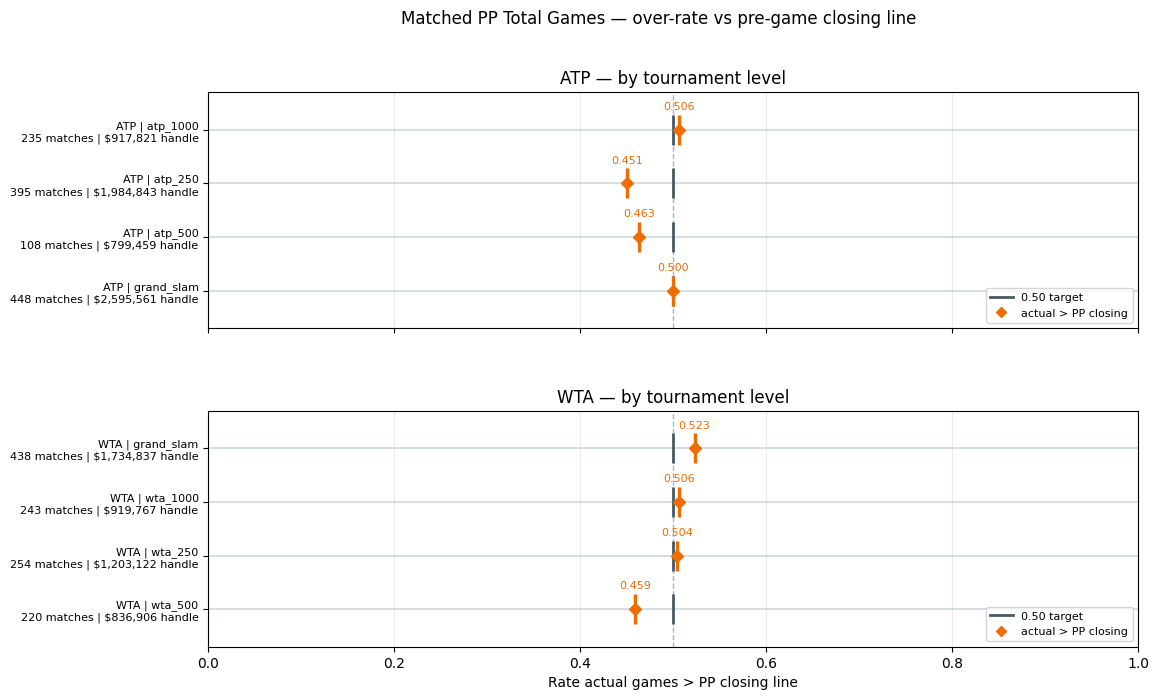

In [19]:
import matplotlib.pyplot as plt
import numpy as np

plot_src = pp_matched.copy()
plot_src["closing_line"] = pd.to_numeric(plot_src["closing_line"], errors="coerce")
plot_src["settled_score"] = pd.to_numeric(plot_src["settled_score"], errors="coerce")
plot_src["category_name"] = plot_src["category_name"].astype("string").fillna("Unknown")
plot_src["competition_level"] = plot_src["competition_level"].astype("string").fillna("unknown")
plot_src["level_label"] = (
    plot_src["category_name"].str.strip() + " | " + plot_src["competition_level"].str.strip()
)

valid = plot_src["closing_line"].notna() & plot_src["settled_score"].notna()
plot_src = plot_src.loc[valid].copy()
plot_src["over_closing"] = (
    plot_src["settled_score"].to_numpy(dtype=float) > plot_src["closing_line"].to_numpy(dtype=float)
).astype(float)

over_by_level = (
    plot_src.groupby("level_label", dropna=False)
    .agg(
        n_games=("game_id", "nunique"),
        over_rate=("over_closing", "mean"),
        total_handle_usd=("total_handle_usd", "sum"),
        avg_closing_line=("closing_line", "mean"),
        avg_settled_score=("settled_score", "mean"),
    )
    .reset_index()
    .sort_values("level_label", ascending=False)
    .reset_index(drop=True)
)

print(f"Matched games in plot: {len(plot_src):,}")
print(f"Overall over-rate vs PP closing: {plot_src['over_closing'].mean():.3f}")
display(over_by_level)


def _draw_closing_over_rate(ax: plt.Axes, df: pd.DataFrame, *, title: str, show_xlabel: bool) -> None:
    if df.empty:
        ax.set_axis_off()
        ax.text(0.5, 0.5, "No rows", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title)
        return

    y_pos = np.arange(len(df))
    for i, (_, row) in enumerate(df.iterrows()):
        y = float(y_pos[i])
        ax.hlines(y, 0.0, 1.0, color="#cfd8dc", linewidth=1.2, zorder=1)
        ax.vlines(0.5, y - 0.28, y + 0.28, color="#455a64", linewidth=2.0, zorder=3)
        x = float(row["over_rate"])
        ax.vlines(x, y - 0.28, y + 0.28, color="#ef6c00", linewidth=2.4, zorder=4)
        ax.plot(x, y, "D", color="#ef6c00", markersize=6, zorder=5)
        ax.text(
            x,
            y + 0.34,
            f"{x:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            color="#ef6c00",
        )

    ax.axvline(0.5, color="#90a4ae", linestyle="--", linewidth=1.0, alpha=0.8, zorder=0)
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(-0.7, len(df) - 0.3)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(
        [
            f"{row['level_label']}\n{int(row['n_games'])} matches | ${row['total_handle_usd']:,.0f} handle"
            for _, row in df.iterrows()
        ],
        fontsize=8,
    )
    if show_xlabel:
        ax.set_xlabel("Rate actual games > PP closing line")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)
    ax.plot([], [], color="#455a64", linewidth=2.0, label="0.50 target")
    ax.plot([], [], "D", color="#ef6c00", markersize=5.5, label="actual > PP closing")
    ax.legend(loc="lower right", fontsize=8)


atp_df = over_by_level.loc[over_by_level["level_label"].str.startswith("ATP", na=False)].copy()
wta_df = over_by_level.loc[over_by_level["level_label"].str.startswith("WTA", na=False)].copy()
other_df = over_by_level.loc[
    ~over_by_level["level_label"].str.startswith(("ATP", "WTA"), na=False)
].copy()

panels = [
    (atp_df, "ATP — by tournament level"),
    (wta_df, "WTA — by tournament level"),
]
if not other_df.empty:
    panels.append((other_df, "Other categories — by tournament level"))

n_rows = [max(len(df), 1) for df, _ in panels]
fig_h = 0.55 * sum(n_rows) + 2.8
fig, axes = plt.subplots(
    len(panels),
    1,
    figsize=(12, fig_h),
    sharex=True,
    gridspec_kw={"height_ratios": n_rows, "hspace": 0.35},
)
if len(panels) == 1:
    axes = [axes]

fig.suptitle("Matched PP Total Games — over-rate vs pre-game closing line", y=0.995)
for i, (df, title) in enumerate(panels):
    _draw_closing_over_rate(
        axes[i],
        df,
        title=title,
        show_xlabel=(i == len(panels) - 1),
    )

plt.tight_layout()
plt.show()

## 8. Hold by tournament level

Core Total Games hold (`xGGR / handle`) on matched PP ↔ SportRadar games, June–September 2026.

,level_label,n_games,total_handle_usd,total_xggr_usd,hold_pct
1,ATP | grand_slam,448,2.595561e+06,662944.226933,25.541463
3,ATP | atp_250,395,1.984843e+06,601206.646844,30.289883
0,WTA | grand_slam,438,1.734837e+06,437461.229445,25.216271
7,WTA | wta_250,254,1.203122e+06,430042.877282,35.743908
5,WTA | wta_1000,243,9.197665e+05,302148.982148,32.850617
4,ATP | atp_1000,235,9.178210e+05,300019.347677,32.688219
6,WTA | wta_500,220,8.369058e+05,275262.305590,32.890477
2,ATP | atp_500,108,7.994585e+05,217031.576081,27.147322


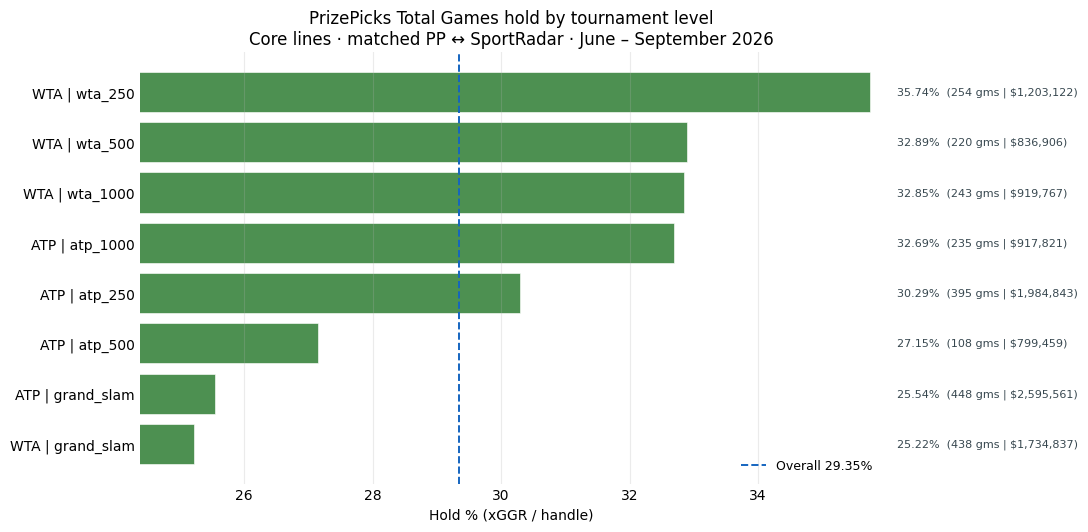

Overall hold: 29.35% on $10,992,315 handle across 2,341 games


In [21]:
hold_src = pp_matched.copy()
hold_src["category_name"] = hold_src["category_name"].astype("string").fillna("Unknown")
hold_src["competition_level"] = hold_src["competition_level"].astype("string").fillna("unknown")
hold_src["level_label"] = (
    hold_src["category_name"].str.strip() + " | " + hold_src["competition_level"].str.strip()
)
hold_src["total_handle_usd"] = pd.to_numeric(hold_src["total_handle_usd"], errors="coerce")
hold_src["total_xggr_usd"] = pd.to_numeric(hold_src["total_xggr_usd"], errors="coerce")

hold_by_level = (
    hold_src.groupby("level_label", dropna=False)
    .agg(
        n_games=("game_id", "nunique"),
        total_handle_usd=("total_handle_usd", "sum"),
        total_xggr_usd=("total_xggr_usd", "sum"),
    )
    .reset_index()
)
hold_by_level["hold_pct"] = (
    100.0 * hold_by_level["total_xggr_usd"] / hold_by_level["total_handle_usd"]
).where(hold_by_level["total_handle_usd"] > 0)
hold_by_level = hold_by_level.sort_values("hold_pct", ascending=True).reset_index(drop=True)

display(hold_by_level.sort_values("total_handle_usd", ascending=False))

overall_handle = hold_by_level["total_handle_usd"].sum()
overall_xggr = hold_by_level["total_xggr_usd"].sum()
overall_hold = 100.0 * overall_xggr / overall_handle if overall_handle else float("nan")

fig_h = max(4.5, 0.45 * len(hold_by_level) + 2.0)
fig, ax = plt.subplots(figsize=(12.5, fig_h))

colors = np.where(hold_by_level["hold_pct"] >= 0, "#2e7d32", "#c62828")
bars = ax.barh(
    hold_by_level["level_label"],
    hold_by_level["hold_pct"],
    color=colors,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.5,
)

ax.axvline(0.0, color="#455a64", linewidth=1.2)
ax.axvline(overall_hold, color="#1565c0", linestyle="--", linewidth=1.4, label=f"Overall {overall_hold:.2f}%")

x_max = float(np.nanmax(hold_by_level["hold_pct"]))
span = max(x_max, 1.0)
ax.set_xlim(0.0, x_max + 0.02 * span)
label_x = x_max + 0.04 * span

for bar, (_, row) in zip(bars, hold_by_level.iterrows()):
    ax.text(
        label_x,
        bar.get_y() + bar.get_height() / 2,
        f"{float(row['hold_pct']):.2f}%  ({int(row['n_games'])} gms | ${row['total_handle_usd']:,.0f})",
        va="center",
        ha="left",
        fontsize=8,
        color="#37474f",
        clip_on=False,
    )

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis="both", length=0)
ax.set_xlabel("Hold % (xGGR / handle)")
ax.set_title(
    "PrizePicks Total Games hold by tournament level\n"
    "Core lines · matched PP ↔ SportRadar · June – September 2026"
)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right", fontsize=9, frameon=False)
fig.subplots_adjust(right=0.72)
plt.show()

print(
    f"Overall hold: {overall_hold:.2f}% on ${overall_handle:,.0f} handle "
    f"across {int(hold_by_level['n_games'].sum()):,} games"
)